# PathSnap — Dataset Exploration (EDA) + Folium Maps (executed)
**Owner:** Poojitha

**Goal:** understand the raw data before building the map-matching pipeline: what each file contains, how big the trips are, data-quality problems, and how GPS points relate to the road network and the reference route.

**Partitions analysed:** **train (80 trips)** and **student_test (10 trips)**. The evaluator partition is not available to us and is never used.

*This notebook was executed end to end; every output below is the real result of running the cell.*

## Step 1 — Setup
**What we say:** On Colab, the notebook mounts Drive (dataset) and clones our GitHub repo. Run locally, it switches into the repo's `src/` folder. The EDA logic lives in `src/eda.py` and `src/make_map.py`.

In [1]:
# Works on Google Colab (clones repo, data from Drive) or locally inside the repo
import os, sys
try:
    import google.colab  # noqa
    from google.colab import drive; drive.mount('/content/drive')
    !git clone -q https://github.com/GTX-Pradeep/Path_Snap_PT_096.git /content/pathsnap
    !pip install -q pyarrow folium
    os.environ['PATHSNAP_DATA'] = '/content/drive/MyDrive/Student folder'   # <- dataset location
    os.chdir('/content/pathsnap/src')
except ImportError:
    os.chdir(os.path.join(os.path.dirname(os.path.abspath('.')), 'src') if os.path.basename(os.path.abspath('.')) == 'notebooks' else 'src')
sys.path.insert(0, '.')
print('working dir:', os.getcwd())

working dir: /home/user/pathsnap/src


## Step 2 — Look at the raw files of one trip
**What we say:** Each trip folder has 4 whitespace-separated files with no header:
* **`.track`**: longitude, latitude, timestamp (s). These are the noisy GPS observations, about 1 per second.
* **`.nodes`**: longitude, latitude of road-network nodes (row index = node id).
* **`.arcs`**: from_node, to_node. These are **directed road segments** (row index = arc id).
* **`.route`**: the ordered list of arc ids the vehicle actually drove (the reference route).

Important: a row in `.track` does **not** correspond to a row in `.nodes` or `.arcs`. Linking GPS points to arcs is exactly the problem we solve.

In [2]:
from data_loader import load_trip, list_trips
trip = load_trip('train', '00000010')
for k in ['track', 'nodes', 'arcs']:
    print(f'--- .{k}: {trip[k].shape[0]} rows'); print(trip[k].head(3).to_string(), '\n')
print('--- .route:', len(trip['route']), 'arcs, first 10:', trip['route'][:10])
print('\ntrain trips:', len(list_trips('train')), '| student_test trips:', len(list_trips('student_test')))

--- .track: 2711 rows
         lon        lat    t
0  37.365267  55.818069  1.0
1  37.365277  55.818044  2.0
2  37.365371  55.818065  3.0 

--- .nodes: 8502 rows
         lon        lat
0  37.374038  55.790758
1  37.372683  55.789246
2  37.372289  55.788784 

--- .arcs: 15715 rows
   u    v
0  0  224
1  1   35
2  2    1 

--- .route: 210 arcs, first 10: [ 5144 11558 11560 11556 11554   967 10434   964  6978   975]

train trips: 80 | student_test trips: 10


## Step 3 — Inventory and data-quality checks for all 90 trips
**What we say:** For every trip we compute file sizes, number of GPS points, nodes, arcs and route length; **missing values** and invalid coordinates; **timestamp ordering**; the share of 1-second steps; **gaps** (largest time gap, gaps over 5 s); the largest jump between consecutive points; geographic extent; and **road-network connectivity** (weak and strong components, isolated nodes). We also check whether consecutive reference arcs connect head-to-tail.

In [3]:
!python eda.py > ../results/eda/eda_log.txt
import pandas as pd
pd.set_option('display.width', 200)
inv = pd.read_csv('../results/eda/inventory.csv')
print(inv.groupby('partition').size().rename('trips'))
inv[['partition','trip','n_gps','n_nodes','n_arcs','route_len','missing_values','pct_dt_eq_1s','max_gap_s','max_jump_m','track_length_km','weak_components','isolated_nodes']].head(10)

partition
student_test    10
train           80
Name: trips, dtype: int64


,partition,trip,n_gps,n_nodes,n_arcs,route_len,missing_values,pct_dt_eq_1s,max_gap_s,max_jump_m,track_length_km,weak_components,isolated_nodes
0,train,1,1315,88809,165790,525,0,98.097412,16.0,72.420783,50.200570,175,0
1,train,2,7243,7936,16139,262,0,97.445457,160.0,37.281571,55.872495,14,0
2,train,3,821,9138,18028,79,0,99.634146,2.0,29.128262,8.420036,42,0
3,train,4,1064,7350,15499,320,0,53.809972,51.0,139.475613,27.892954,12,0
4,train,5,1045,898,1579,105,0,100.000000,1.0,63.829481,31.330181,3,0
5,train,6,1450,3259,6757,261,0,99.171843,301.0,46.691683,19.390324,8,0
6,train,8,3093,4995,10421,173,0,99.967658,2.0,70.174567,25.044495,13,0
7,train,10,2711,8502,15715,210,0,100.000000,1.0,39.223825,25.813966,28,0
8,train,11,2828,2649,5393,565,0,99.964627,909.0,50.323648,54.972680,2,0
9,train,12,1608,16376,38599,205,0,99.937772,2.0,55.198178,41.579550,22,0


## Step 4 — Summary by partition
**What we say (key findings):**
* **No missing values and no invalid coordinates** in any trip. Timestamps are strictly increasing.
* Sampling is **nominally 1 Hz** (most steps are exactly 1 s), but some trips have **huge gaps**: trip 90 has a gap of about 42 hours and trip 78 one of about 14.7 hours. Our pipeline must handle gaps, and the HMM will scale its transitions by elapsed time.
* Each trip has its **own road network** of thousands of nodes and arcs, with **no isolated nodes**.
* Consecutive reference arcs are almost always connected, so the route is a valid path in the graph.

In [4]:
summary = pd.read_csv('../results/eda/summary_by_partition.csv', index_col=[0, 1])
summary.xs('mean', level=1).round(2).join(summary.xs('max', level=1).round(1), lsuffix=' (mean)', rsuffix=' (max)').T

,n_gps,n_nodes,n_arcs,route_len,missing_values,pct_dt_eq_1s,max_gap_s,n_gaps_gt_5s,max_jump_m,track_length_km,mean_speed_kmh,weak_components,isolated_nodes,route_consecutive_connected
student_test (mean),1916.00,9068.90,18504.1,347.7,0.0,98.20,25.5,4.4,53.82,29.70,53.53,22.70,0.0,1.0
train (mean),2605.21,24168.56,48461.3,391.7,0.0,93.83,2706.4,15.2,115.91,37.23,48.60,39.01,0.0,1.0
student_test (max),3958.00,26635.00,56027.0,1323.0,0.0,100.00,210.0,39.0,76.80,71.70,78.20,100.00,0.0,1.0
train (max),19313.00,155003.00,307392.0,2266.0,0.0,100.00,153064.0,320.0,887.60,169.30,133.20,421.00,0.0,1.0


## Step 5 — Anomalies: trips with the largest GPS gaps
**What we say:** These trips have the biggest time gaps and jumps. We keep them, but they explain why the pipeline must not assume continuous 1 Hz data.

In [5]:
pd.read_csv('../results/eda/anomalies_top10.csv')

,partition,trip,max_gap_s,max_jump_m,n_gaps_gt_5s
0,train,90,153064.0,35.621543,20
1,train,78,52810.0,214.932485,124
2,train,69,2658.0,66.185829,2
3,train,21,2161.0,45.951041,2
4,train,11,909.0,50.323648,1
5,train,42,670.0,58.407892,45
6,train,81,536.0,109.245435,129
7,train,24,458.0,65.718831,4
8,train,44,341.0,36.206826,2
9,train,84,312.0,49.225169,4


## Step 6 — Reference-route limitation (label quality)
**What we say:** The guidelines warn that reference routes may not be perfect. We aligned GPS points to the route and measured the distance from each point to its reference arc. In **trips 33 and 54**, most GPS points are **more than 100 m** from the reference route, so the route does not describe where those points are. We therefore drop training points whose reference arc is more than 50 m away. **student_test is never filtered.**

In [6]:
import numpy as np
from features import build_geometry, reference_labels
rows = []
for t in ['00000033', '00000054', '00000010', '00000072']:
    tr = load_trip('train', t); g = build_geometry(tr)
    _, d = reference_labels(g, tr['route'])
    rows.append(dict(trip=t, gps_points=len(d), median_dist_to_route_m=round(float(np.median(d)), 1),
                     p90_m=round(float(np.percentile(d, 90)), 1), share_over_50m=round(float((d > 50).mean()), 3)))
pd.DataFrame(rows)

,trip,gps_points,median_dist_to_route_m,p90_m,share_over_50m
0,00000033,5844,122.4,139.6,0.589
1,00000054,19313,140.0,196.6,0.894
2,00000010,2711,5.2,13.3,0.000
3,00000072,969,5.7,12.3,0.000


## Step 7 — EDA plots
**What we say:**
1. **Trip distributions**: GPS points per trip, largest gap per trip, mean speed per trip (train vs student_test).
2. **All training trajectories** on lon/lat axes, showing the geographic extent of the dataset.
3. **Sampling intervals** (log scale): almost all steps are 1 s, with a long tail of gaps.
4. **Road-network size** per trip (nodes vs arcs).
5. **One trip**: road network (grey), reference route (green), GPS (blue). GPS points lie *near* but not *on* the roads, which is the noise we must correct.

trip_distributions


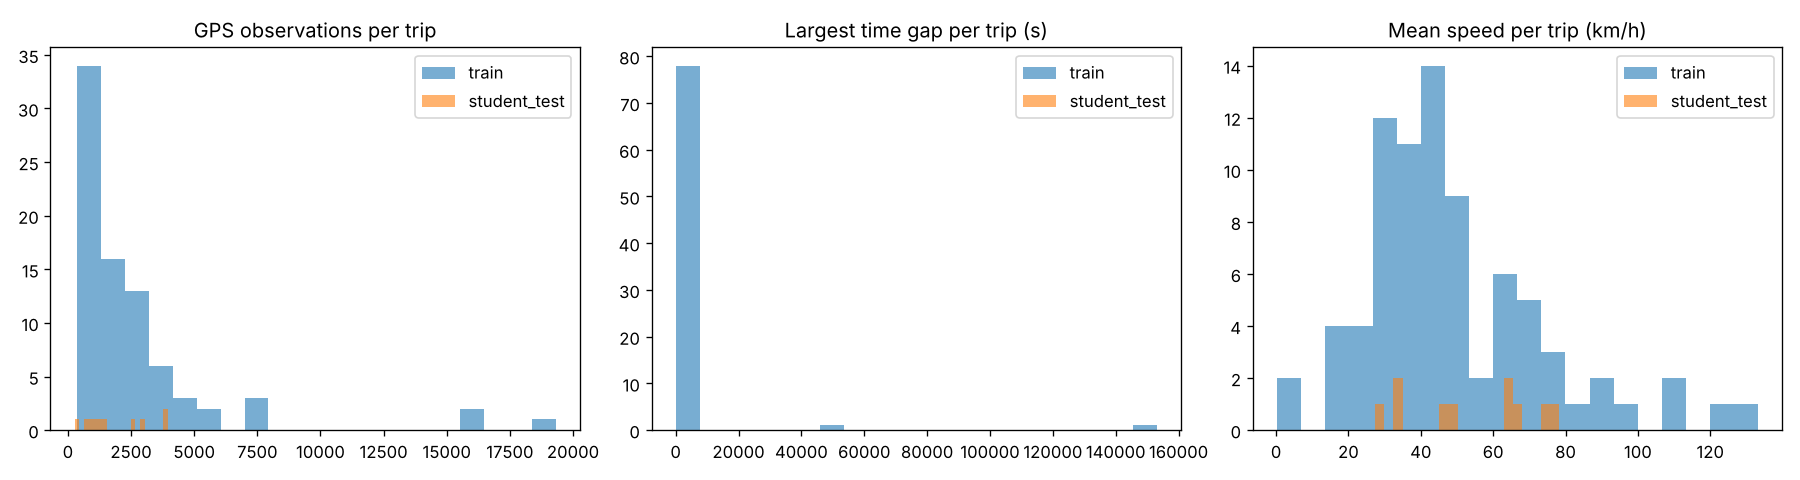

train_trajectories


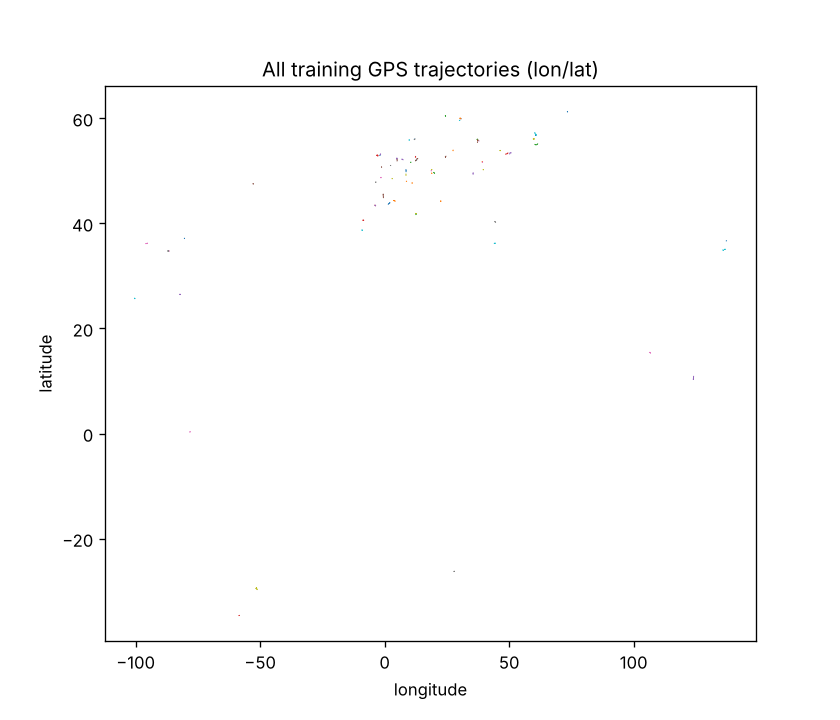

sampling_intervals


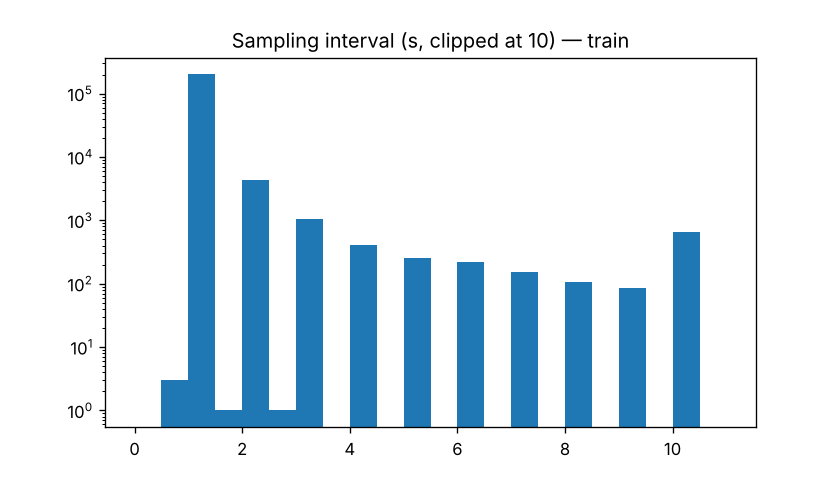

network_size


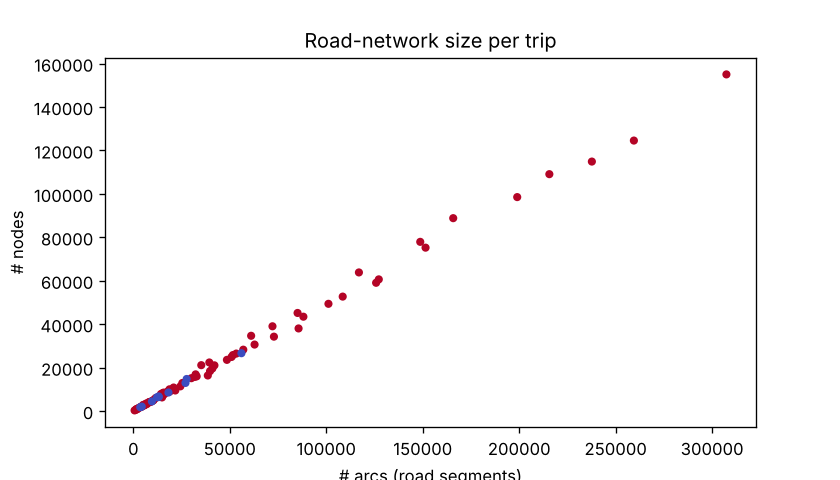

road_network_train_00000010


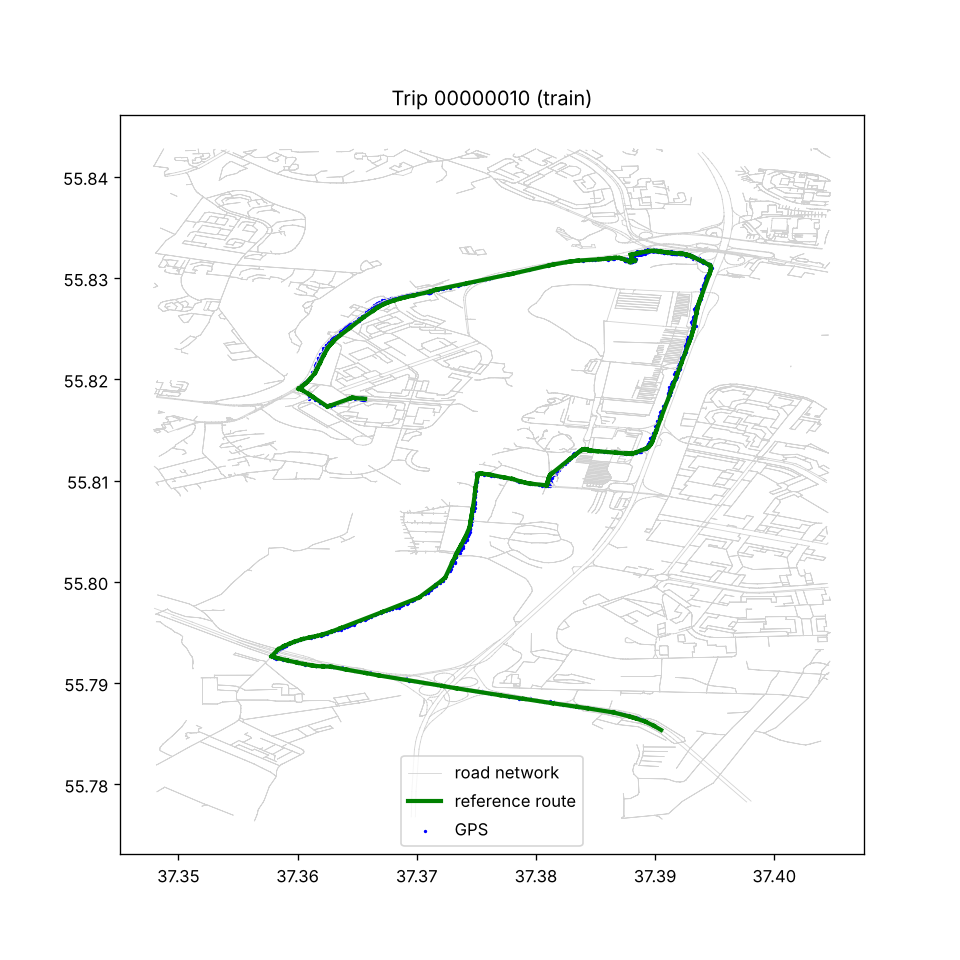

In [7]:
from IPython.display import Image, display
for f in ['trip_distributions', 'train_trajectories', 'sampling_intervals', 'network_size', 'road_network_train_00000010']:
    print(f); display(Image(f'../results/eda/{f}.png'))

## Step 8 — Coordinates: why we project to metres
**What we say:** Longitude and latitude are **angles**. The metres per degree of longitude shrink with latitude (cos φ), and the trips lie in different cities worldwide (latitudes −35° to 62°), so Euclidean distance in degrees is wrong. We project each trip to a **local equirectangular plane in metres** centred on the trip, which is accurate at city scale. All distances (candidates, features, alignment) are computed in metres.

In [8]:
from data_loader import project, clean_track
tr = clean_track(trip['track'])
lat0 = tr.lat.mean()
print('latitude of trip centre: %.3f deg' % lat0)
print('1 deg latitude  = %.0f m' % (np.radians(1) * 6371000))
print('1 deg longitude = %.0f m  (shrinks by cos(latitude))' % (np.radians(1) * 6371000 * np.cos(np.radians(lat0))))
x, y = project(tr.lon, tr.lat, tr.lon.mean(), lat0)
step = np.hypot(np.diff(x), np.diff(y))
print('median distance between consecutive GPS points: %.1f m (about %.0f km/h at 1 Hz)' % (np.median(step), np.median(step) * 3.6))

latitude of trip centre: 55.825 deg
1 deg latitude  = 111195 m
1 deg longitude = 62461 m  (shrinks by cos(latitude))
median distance between consecutive GPS points: 8.4 m (about 30 km/h at 1 Hz)


## Step 9 — Interactive Folium map
**What we say:** The layers are **raw GPS** (blue dots), **reference route** (green) and **road network** (grey, toggle it on). Use the **layer control** (top right) to switch layers. The map shows the GPS drifting off the road, the problem PathSnap solves. It is saved to `maps/trip_train_00000010.html`.

In [9]:
from make_map import trip_map
m = trip_map('train', '00000010')
m.save('../maps/trip_train_00000010.html')
m

## Conclusions from EDA, and the decisions they led to
| Finding | Decision |
|---|---|
| Degrees are not metres | local metric projection per trip |
| GPS is near, but not on, the roads | generate the **8 nearest arcs** as candidates per GPS point |
| Arcs are directed; two-way roads have two arcs | **heading-difference** feature |
| Dense junctions are ambiguous | features: candidates within 30 m, distance relative to nearest candidate, previous/next point distances |
| `.route` has no timestamps | **monotonic DP alignment** gives a reference arc per GPS point |
| Some reference routes don't match the GPS (trips 33, 54) | drop training points more than 50 m from the reference; never filter test |
| Large time gaps exist | HMM transitions must account for gaps (next phase) |
| Trips must not leak across folds | **GroupKFold by trip** for all models |